流式输出大模型调用结果

In [1]:
import os
from dotenv import load_dotenv
from langchain_community.chat_models import ChatTongyi
from rich import prompt

load_dotenv()

# 创建大语言模型实例
llm = ChatTongyi(
    model="qwen-plus",
    temperature=0.5,
    api_key=os.environ.get("DASHSCOPE_API_KEY"),
    streaming=True,
)

C:\Users\Admin\AppData\Local\Temp\ipykernel_20620\706524034.py:3: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.chat_models import ChatTongyi


In [4]:
from langgraph.graph import StateGraph, MessagesState, START
from langgraph.checkpoint.memory import InMemorySaver

def call_mode(state: MessagesState):
    response = llm.invoke(state["messages"])
    return {"messages": response}

builder = StateGraph(MessagesState)
builder.add_node(call_mode)
builder.add_edge(START, "call_mode")

graph = builder.compile()

for chuck in graph.stream(
        {"messages": [{"role": "user", "content": "湖南的省会是哪里？"}]},
        stream_mode="messages",
):
    print(chuck)

(AIMessageChunk(content='湖南', additional_kwargs={}, response_metadata={}, id='lc_run--01a0e5fc-7323-7620-8e5d-14c5be3bf266', tool_calls=[], invalid_tool_calls=[], tool_call_chunks=[]), {'ls_integration': 'langchain_chat_model', 'langgraph_step': 1, 'langgraph_node': 'call_mode', 'langgraph_triggers': ('branch:to:call_mode',), 'langgraph_path': ('__pregel_pull', 'call_mode'), 'langgraph_checkpoint_ns': 'call_mode:bc866fa6-89c2-5ebf-4bd6-c4680149a3a8', 'checkpoint_ns': 'call_mode:bc866fa6-89c2-5ebf-4bd6-c4680149a3a8', 'ls_provider': 'tongyi', 'ls_model_type': 'chat', 'ls_model_name': 'qwen-plus', 'lc_versions': {'langchain-core': '1.6.3', 'langchain': '1.3.18'}})
(AIMessageChunk(content='的省会', additional_kwargs={}, response_metadata={}, id='lc_run--01a0e5fc-7323-7620-8e5d-14c5be3bf266', tool_calls=[], invalid_tool_calls=[], tool_call_chunks=[]), {'ls_integration': 'langchain_chat_model', 'langgraph_step': 1, 'langgraph_node': 'call_mode', 'langgraph_triggers': ('branch:to:call_mode',), '

大模型消息持久化

In [5]:
checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)
config = {
    "configurable": {"thread_id": 1},
}
for chuck in graph.stream(
        {"messages": [{"role": "user", "content": "湖南的省会是哪里？"}]},
        stream_mode="values",
        config=config,
):
    chuck["messages"][-1].pretty_print()

for chuck in graph.stream(
        {"messages": [{"role": "user", "content": "那河北呢？"}]},
        stream_mode="values",
        config=config,
):
    chuck["messages"][-1].pretty_print()


================================ Human Message =================================

湖南的省会是哪里？
================================== Ai Message ==================================

湖南的省会是**长沙市**。
================================ Human Message =================================

那河北呢？
================================== Ai Message ==================================

河北省的省会是**石家庄市**。


Human-In-Loop 人类干预

In [9]:
# 构建一个带有个Human-In-Loop的Graph

from operator import add

from langchain_core.messages import AnyMessage
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.constants import START, END
from langgraph.graph import StateGraph

from typing import Literal, TypedDict, Annotated
from langgraph.types import interrupt, Command

class State(TypedDict):
    messages: Annotated[list[AnyMessage], add]

def human_approval(state: State) -> Command[Literal["call_llm", END]]:
    is_approval = interrupt(
        {"question": "是否同意调用大语言模型？"}
    )
    if is_approval:
        return Command(goto="call_llm")
    else:
        return Command(goto=END)

def call_llm(state: State) -> State:
    response = llm.invoke(state["messages"])
    return {"messages": [response]}

builder = StateGraph(State)

# 将节点添加到图中并连接到相关节点
# Add the node to the graph in an appropriate location
# and connect it to the relevant nodes.

builder.add_node("human_approval", human_approval)
builder.add_node("call_llm", call_llm)

builder.add_edge(START, "human_approval")

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

In [12]:
from langchain_core.messages import HumanMessage

# 提交任务，等待确认
thread_config = {"configurable": {"thread_id": 1}}
graph.invoke({"messages": [HumanMessage(content="湖南的省会是哪里？")]}, config=thread_config)
# 执行后会中断任务，等待确认

{'messages': [HumanMessage(content='湖南的省会是哪里？', additional_kwargs={}, response_metadata={}),
  AIMessage(content='湖南的省会是**长沙市**。', additional_kwargs={}, response_metadata={'finish_reason': 'stop', 'request_id': 'f2bbf2ae-8635-9384-b7fe-1b08e87b7153', 'token_usage': {'input_tokens': 15, 'output_tokens': 9, 'total_tokens': 24, 'prompt_tokens_details': {'cached_tokens': 0}}}, id='lc_run--01a0e661-9498-7643-b032-df16a96beb43', tool_calls=[], invalid_tool_calls=[]),
  HumanMessage(content='湖南的省会是哪里？', additional_kwargs={}, response_metadata={})],
 '__interrupt__': [Interrupt(value={'question': '是否同意调用大语言模型？'}, id='5e1f4d8bc2473718a83590aaf6b23c8c')]}

In [13]:
# 确认同意，继续执行任务
# final_result = graph.invoke(Command(resume=True), config=thread_config)
# print(final_result)
# 不同意，终止任务
final_result = graph.invoke(Command(resume=False), config=thread_config)
print(final_result)

{'messages': [HumanMessage(content='湖南的省会是哪里？', additional_kwargs={}, response_metadata={}), AIMessage(content='湖南的省会是**长沙市**。', additional_kwargs={}, response_metadata={'finish_reason': 'stop', 'request_id': 'f2bbf2ae-8635-9384-b7fe-1b08e87b7153', 'token_usage': {'input_tokens': 15, 'output_tokens': 9, 'total_tokens': 24, 'prompt_tokens_details': {'cached_tokens': 0}}}, id='lc_run--01a0e661-9498-7643-b032-df16a96beb43', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='湖南的省会是哪里？', additional_kwargs={}, response_metadata={})]}


Time Travel 时间回溯

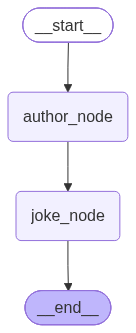

In [2]:
# 构建一个图。图中连个步骤：第一步让大模型推荐一个有名的作家；第二步，让大模型用推荐的作家的风格写一个100字以内的笑话。
from typing import TypedDict
from typing_extensions import NotRequired
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.constants import START, END
from langgraph.graph import StateGraph

class State(TypedDict):
    author: NotRequired[str]
    joke: NotRequired[str]

def author_node(state: State):
    prompt = "帮我推荐一位受人们欢迎的作家，只需要给出作家的名字即可。"
    author = llm.invoke(prompt)
    return {"author": author}

def joke_node(state: State):
    prompt = f"请用作家{state['author']}的风格写一个100字以内的笑话。"
    joke = llm.invoke(prompt)
    return {"joke": joke}

builder = StateGraph(State)
builder.add_node(author_node)
builder.add_node(joke_node)

builder.add_edge(START, "author_node")
builder.add_edge("author_node", "joke_node")
builder.add_edge("joke_node", END)

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)
graph

In [10]:
# 正常执行一个图
import uuid
config = {"configurable": {"thread_id": uuid.uuid4().hex}}
state = graph.invoke({}, config=config)
print(state["author"])
print("=" * 50)
print(state["joke"])
print("=" * 50)
print(config["configurable"]["thread_id"])

content='村上春树' additional_kwargs={} response_metadata={'finish_reason': 'stop', 'request_id': 'f9236132-bbef-938d-9204-af59beecb3a2', 'token_usage': {'input_tokens': 23, 'output_tokens': 4, 'total_tokens': 27, 'prompt_tokens_details': {'cached_tokens': 0}}} id='lc_run--01a0f03b-1dcc-73e3-975a-9945c0e4ad85' tool_calls=[] invalid_tool_calls=[]
content='凌晨三点，冰箱里只剩一罐啤酒和半块干酪。我打开罐子，气泡声像老式收音机调频——嘶、滋、然后突然清晰：  \n“喂，你确定要喝这个？它刚梦见自己是海。”  \n我愣住。  \n干酪默默掉下一小粒碎屑，像在点头。  \n（我喝了。梦里整片太平洋在易拉罐底轻轻晃。）' additional_kwargs={} response_metadata={'finish_reason': 'stop', 'request_id': '60412ba6-e222-9c9c-ba0f-fce3187c1424', 'token_usage': {'input_tokens': 163, 'output_tokens': 96, 'total_tokens': 259, 'prompt_tokens_details': {'cached_tokens': 0}}} id='lc_run--01a0f03b-1f6b-7bc0-b236-d2c9b126e739' tool_calls=[] invalid_tool_calls=[]
cef4590a30e542a0bc18e299b8603d36


In [11]:
# 检查所有checkpoint检查点
states = list(graph.get_state_history(config))
for state in states:
    print(state.next)
    print(state.config["configurable"]["checkpoint_id"])
    print("=" * 50)

()
1f1bc7a1-a3ce-6e89-8002-6c9bc8cf5151
('joke_node',)
1f1bc7a1-8fc7-6cc7-8001-d24f7cffd287
('author_node',)
1f1bc7a1-8bd2-666b-8000-9f8d53ec1748
('__start__',)
1f1bc7a1-8bd0-6fbd-bfff-e9db6bf1c1c4


In [12]:
# 选定一个checkpoint检查点。这里选择author_node节点的checkpoint检查点，让大模型重新推荐一个作家。
selected_state = states[1]
print(selected_state.values)
print(selected_state.next)

{'author': AIMessage(content='村上春树', additional_kwargs={}, response_metadata={'finish_reason': 'stop', 'request_id': 'f9236132-bbef-938d-9204-af59beecb3a2', 'token_usage': {'input_tokens': 23, 'output_tokens': 4, 'total_tokens': 27, 'prompt_tokens_details': {'cached_tokens': 0}}}, id='lc_run--01a0f03b-1dcc-73e3-975a-9945c0e4ad85', tool_calls=[], invalid_tool_calls=[])}
('joke_node',)


In [13]:
# 为了后面的重演，更新state，为可选步骤。
new_config = graph.update_state(selected_state.config, values={"author": "远瞳"})
print(new_config)

{'configurable': {'thread_id': 'cef4590a30e542a0bc18e299b8603d36', 'checkpoint_ns': '', 'checkpoint_id': '1f1bc7a2-4f36-6a44-8002-5965c6ddd774'}}


In [14]:
# 接下来，指定thread_id和checkpoint_id，进行重演
graph.invoke(None, new_config)

{'author': '远瞳',
 'joke': AIMessage(content='“您订购的‘宇宙级静音’已生效。”  \n工程师擦着汗递来说明书：“本产品通过局部时空折叠，使声波在抵达耳膜前先完成一次退休手续——它刚领完养老金，正在银河系养老院跳广场舞。”  \n客户点头：“挺好。”  \n三秒后，他听见自己心跳声轰然炸响。  \n“哦，”工程师挠头，“忘了说——静音只针对外部声音。您体内那台老式柴油机……我们管不了。”', additional_kwargs={}, response_metadata={'finish_reason': 'stop', 'request_id': 'c1ea7c7e-32d8-9209-8fe8-5e31154b6f16', 'token_usage': {'input_tokens': 25, 'output_tokens': 111, 'total_tokens': 136, 'prompt_tokens_details': {'cached_tokens': 0}}}, id='lc_run--01a0f03b-a031-7f61-a7ac-08be79084351', tool_calls=[], invalid_tool_calls=[])}